In [1]:
import pandas as pd


In [19]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
df=pd.read_csv("HR-Employee-Attrition.csv")

In [34]:
df.sample(5)

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
841,24,No,Travel_Rarely,477,Research & Development,24,3,Medical,1,1173,...,4,80,0,6,2,3,4,3,1,2
355,26,No,Travel_Rarely,933,Sales,1,3,Life Sciences,1,476,...,2,80,1,8,3,3,8,7,7,7
868,28,No,Travel_Rarely,1179,Research & Development,19,4,Medical,1,1216,...,3,80,3,6,2,3,6,5,3,3
576,27,No,Travel_Frequently,829,Sales,8,1,Marketing,1,800,...,2,80,1,5,3,3,4,2,1,1
324,30,No,Travel_Rarely,1275,Research & Development,28,2,Medical,1,441,...,4,80,2,11,2,3,10,8,1,9


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

In [7]:
df.shape

(1470, 35)

In [9]:
miss=df.isnull().sum()
print(miss)

Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSince

In [11]:
dup=df.duplicated().sum()
print(dup)

0


In [12]:


attrition_counts = df["Attrition"].value_counts()

print(attrition_counts)

Attrition
No     1233
Yes     237
Name: count, dtype: int64


In [13]:
attrition_percentage = df["Attrition"].value_counts(normalize=True) * 100

print(attrition_percentage)

Attrition
No     83.877551
Yes    16.122449
Name: proportion, dtype: float64


In [18]:
total_employees = len(df)
employees_left = (df["Attrition"] == "Yes").sum()

attrition_rate = (employees_left / total_employees) * 100

print("Total Employees:", total_employees)
print("Employees Left:", employees_left)
print("Attrition Rate: {:.2f}%".format(attrition_rate))

Total Employees: 1470
Employees Left: 237
Attrition Rate: 16.12%


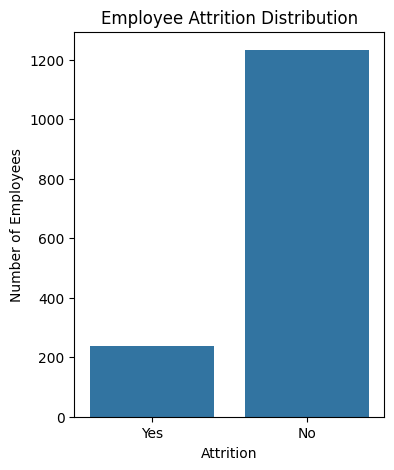

In [24]:
plt.figure(figsize=(4,5))

sns.countplot(data=df, x="Attrition")

plt.title("Employee Attrition Distribution")
plt.xlabel("Attrition")
plt.ylabel("Number of Employees")

plt.show()

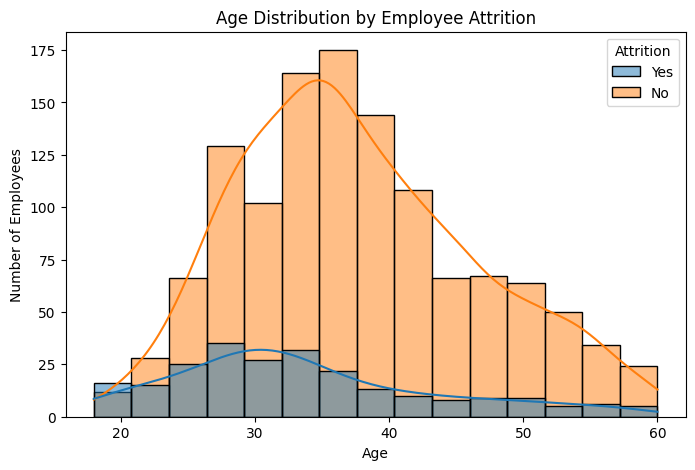

In [25]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x="Age",
    hue="Attrition",
    bins=15,
    kde=True
)

plt.title("Age Distribution by Employee Attrition")
plt.xlabel("Age")
plt.ylabel("Number of Employees")

plt.show()

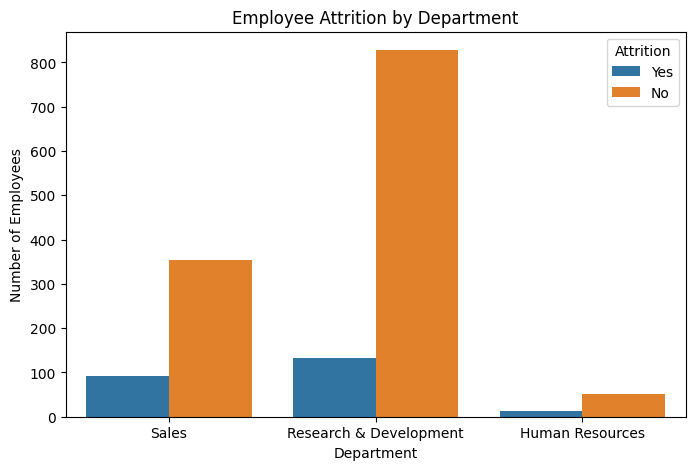

In [26]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="Department",
    hue="Attrition"
)

plt.title("Employee Attrition by Department")
plt.xlabel("Department")
plt.ylabel("Number of Employees")

plt.show()

In [27]:
department_attrition = pd.crosstab(
    df["Department"],
    df["Attrition"],
    normalize="index"
) * 100

print(department_attrition.round(2))

Attrition                  No    Yes
Department                          
Human Resources         80.95  19.05
Research & Development  86.16  13.84
Sales                   79.37  20.63


In [28]:
salary_analysis = df.groupby("Attrition")["MonthlyIncome"].mean()

print(salary_analysis)

Attrition
No     6832.739659
Yes    4787.092827
Name: MonthlyIncome, dtype: float64


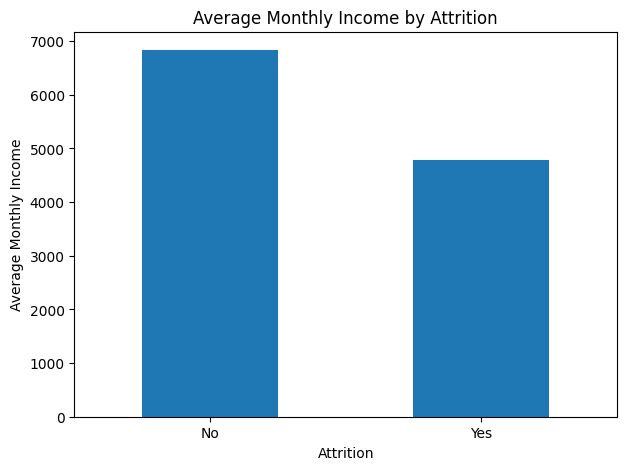

In [33]:
plt.figure(figsize=(7,5))

salary_analysis.plot(kind="bar")

plt.title("Average Monthly Income by Attrition")
plt.xlabel("Attrition")
plt.ylabel("Average Monthly Income")

plt.xticks(rotation=0)

plt.show()

In [35]:
overtime_percentage = pd.crosstab(
    df["OverTime"],
    df["Attrition"],
    normalize="index"
) * 100

print(overtime_percentage.round(2))

Attrition     No    Yes
OverTime               
No         89.56  10.44
Yes        69.47  30.53
